In [1]:
# ============================================
# STEP 1: IMPORT LIBRARIES
# ============================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

import joblib

print("Libraries imported successfully")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully
TensorFlow version: 2.20.0


In [3]:
df=pd.read_csv("/content/pose_landmarks.csv")

In [4]:
df.head()

,subject,video,source,frame,time_seconds,x_0,y_0,z_0,visibility_0,x_1,...,y_32,z_32,visibility_32,body_height,shoulder_width,hip_width,head_hip_distance,body_angle,body_aspect_ratio,target
0,Subject 2,22.mp4,ADL,0,0.000000,0.650427,0.641179,-0.308870,0.999435,0.662823,...,0.976442,-0.056678,0.922684,0.240951,0.053052,0.025430,0.240951,-150.558161,4.541701,0
1,Subject 2,22.mp4,ADL,5,0.333223,0.649980,0.655973,-0.191512,0.999457,0.662122,...,0.975352,-0.069316,0.925953,0.244444,0.049583,0.024692,0.244444,-148.450047,4.929882,0
2,Subject 2,22.mp4,ADL,10,0.666445,0.650015,0.671449,-0.202262,0.999469,0.662154,...,0.959317,0.084979,0.903759,0.249190,0.054135,0.025209,0.249190,-146.572329,4.603008,0
3,Subject 2,22.mp4,ADL,15,0.999668,0.651747,0.683383,-0.177288,0.999512,0.663414,...,0.950674,0.073077,0.905823,0.246351,0.054606,0.024448,0.246351,-146.820759,4.511314,0
4,Subject 2,22.mp4,ADL,20,1.332890,0.656726,0.689488,-0.184296,0.999555,0.667885,...,0.915498,0.167926,0.906630,0.238885,0.068433,0.027735,0.238885,-149.656536,3.490727,0


In [5]:
df.shape

(6485, 144)

In [6]:
df["target"].value_counts()

,count
target,
0,5048
1,1437


In [7]:
# ============================================
# STEP 4: DATA INSPECTION
# ============================================

print("Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes.value_counts())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicates:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df["target"].value_counts())

print("\nTarget Percentage:")
print(
    df["target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nColumns:")
print(df.columns.tolist())

Shape:
(6485, 144)

Data Types:
float64    139
object       3
int64        2
Name: count, dtype: int64

Missing Values:
0

Duplicates:
0

Target Distribution:
target
0    5048
1    1437
Name: count, dtype: int64

Target Percentage:
target
0    77.84
1    22.16
Name: proportion, dtype: float64

Columns:
['subject', 'video', 'source', 'frame', 'time_seconds', 'x_0', 'y_0', 'z_0', 'visibility_0', 'x_1', 'y_1', 'z_1', 'visibility_1', 'x_2', 'y_2', 'z_2', 'visibility_2', 'x_3', 'y_3', 'z_3', 'visibility_3', 'x_4', 'y_4', 'z_4', 'visibility_4', 'x_5', 'y_5', 'z_5', 'visibility_5', 'x_6', 'y_6', 'z_6', 'visibility_6', 'x_7', 'y_7', 'z_7', 'visibility_7', 'x_8', 'y_8', 'z_8', 'visibility_8', 'x_9', 'y_9', 'z_9', 'visibility_9', 'x_10', 'y_10', 'z_10', 'visibility_10', 'x_11', 'y_11', 'z_11', 'visibility_11', 'x_12', 'y_12', 'z_12', 'visibility_12', 'x_13', 'y_13', 'z_13', 'visibility_13', 'x_14', 'y_14', 'z_14', 'visibility_14', 'x_15', 'y_15', 'z_15', 'visibility_15', 'x_16', 'y_16', 'z_16', 

In [8]:
# ============================================
# STEP 5: EXPLORATORY DATA ANALYSIS
# ============================================

# Numerical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("===================================")
print("NUMERICAL COLUMNS")
print("===================================")

print("Count:", len(numerical_columns))


# Categorical columns
categorical_columns = df.select_dtypes(
    include="object"
).columns.tolist()

print("\n===================================")
print("CATEGORICAL COLUMNS")
print("===================================")

print("Count:", len(categorical_columns))
print(categorical_columns)


# Subject distribution
print("\n===================================")
print("SUBJECT DISTRIBUTION")
print("===================================")

print(df["subject"].value_counts())


# Source distribution
print("\n===================================")
print("SOURCE DISTRIBUTION")
print("===================================")

print(df["source"].value_counts())


# Target by subject
print("\n===================================")
print("TARGET BY SUBJECT")
print("===================================")

print(
    pd.crosstab(
        df["subject"],
        df["target"]
    )
)


# Target by source
print("\n===================================")
print("TARGET BY SOURCE")
print("===================================")

print(
    pd.crosstab(
        df["source"],
        df["target"]
    )
)


# Descriptive statistics
print("\n===================================")
print("DESCRIPTIVE STATISTICS")
print("===================================")

display(df.describe())


# Unique videos
print("\n===================================")
print("UNIQUE VIDEOS")
print("===================================")

print(df["video"].nunique())


# Subject-video combinations
print("\n===================================")
print("SUBJECT-VIDEO GROUPS")
print("===================================")

print(
    df.groupby(
        ["subject", "video"]
    ).ngroups
)

NUMERICAL COLUMNS
Count: 141

CATEGORICAL COLUMNS
Count: 3
['subject', 'video', 'source']

SUBJECT DISTRIBUTION
subject
Subject 2    2121
Subject 4    1621
Subject 3    1615
Subject 1    1128
Name: count, dtype: int64

SOURCE DISTRIBUTION
source
ADL     3812
Fall    2673
Name: count, dtype: int64

TARGET BY SUBJECT
target        0    1
subject             
Subject 1   838  290
Subject 2  1617  504
Subject 3  1230  385
Subject 4  1363  258

TARGET BY SOURCE
target     0     1
source            
ADL     3812     0
Fall    1236  1437

DESCRIPTIVE STATISTICS


,frame,time_seconds,x_0,y_0,z_0,visibility_0,x_1,y_1,z_1,visibility_1,...,y_32,z_32,visibility_32,body_height,shoulder_width,hip_width,head_hip_distance,body_angle,body_aspect_ratio,target
count,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,...,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000,6485.000000
mean,125.659985,4.517023,0.423442,0.414819,-0.131633,0.994777,0.425236,0.404454,-0.132099,0.994911,...,0.781554,-0.003727,0.749640,0.222483,0.061164,0.037469,0.222483,49.890921,7.448440,0.221588
std,90.640947,3.135674,0.146880,0.253848,0.197244,0.010963,0.150051,0.259667,0.194791,0.010519,...,0.136184,0.227692,0.177660,0.080019,0.035955,0.020010,0.080019,87.275798,17.673047,0.415347
min,0.000000,0.000000,0.056318,-0.010955,-1.290545,0.861880,0.047160,-0.025349,-1.308698,0.870126,...,0.162708,-0.849058,0.185606,0.006122,0.000370,0.000130,0.006122,-179.866058,0.087973,0.000000
25%,55.000000,2.009873,0.311938,0.213857,-0.244451,0.995134,0.312597,0.196411,-0.241573,0.995213,...,0.725642,-0.147472,0.644457,0.163611,0.031640,0.022449,0.163611,30.891192,2.329233,0.000000
50%,110.000000,4.018186,0.417812,0.349955,-0.119450,0.998034,0.419514,0.336077,-0.116605,0.997975,...,0.808656,-0.012550,0.785285,0.205905,0.057312,0.035574,0.205905,85.619810,3.752086,0.000000
75%,175.000000,6.416210,0.520288,0.601186,-0.022275,0.999310,0.522691,0.591343,-0.023368,0.999170,...,0.864430,0.151191,0.895257,0.281154,0.087655,0.050579,0.281154,97.179368,7.218070,0.000000
max,520.000000,17.420895,0.924690,1.105091,0.795335,0.999987,0.934434,1.108519,0.784517,0.999983,...,1.133231,1.492809,0.986804,0.475909,0.211565,0.123756,0.475909,179.986730,799.225177,1.000000



UNIQUE VIDEOS
25

SUBJECT-VIDEO GROUPS
83


In [9]:
# ==========================================
# BIVARIATE ANALYSIS
# ==========================================

print("==========================================")
print("BIVARIATE ANALYSIS")
print("==========================================")

# Compare numerical features with target
target_means = df.groupby("target")[numerical_columns].mean().T

display(target_means)

BIVARIATE ANALYSIS


target,0,1
frame,124.700872,129.029228
time_seconds,4.498587,4.581786
x_0,0.421138,0.431538
y_0,0.336400,0.690295
z_0,-0.133299,-0.125782
...,...,...
hip_width,0.035747,0.043520
head_hip_distance,0.234412,0.180577
body_angle,69.572108,-19.246608
body_aspect_ratio,8.167830,4.921314


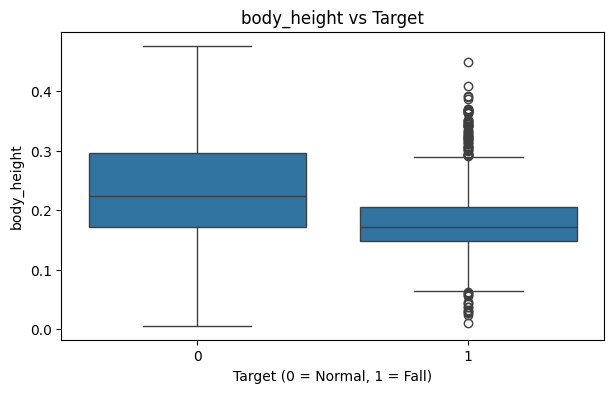

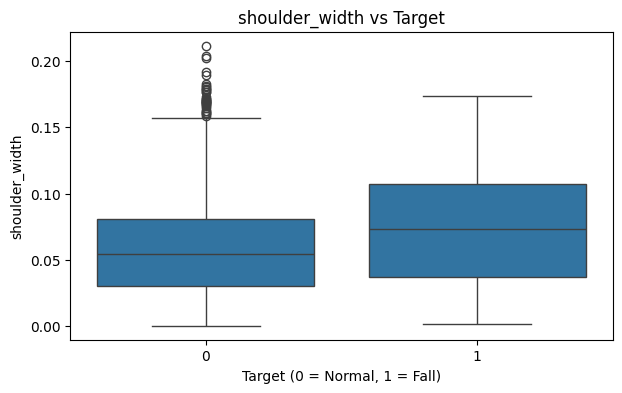

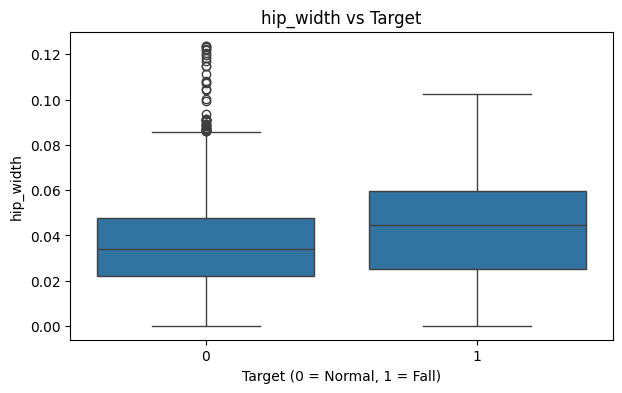

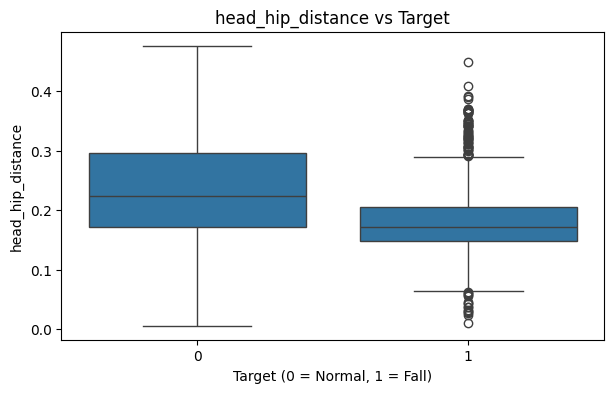

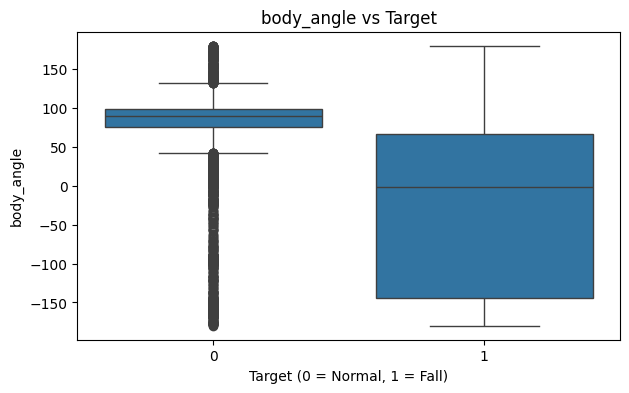

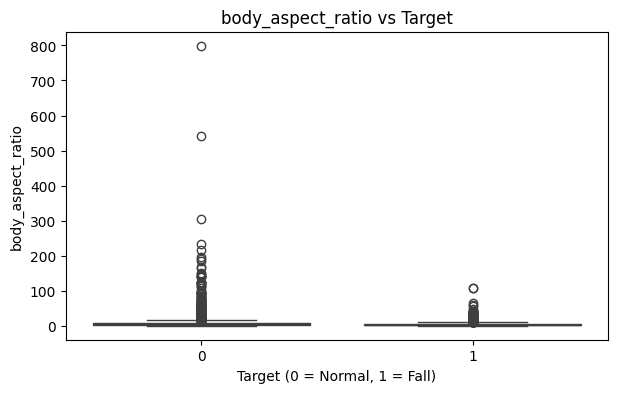

In [10]:
# ==========================================
# BIVARIATE ANALYSIS
# Numerical Features vs Target
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

bivariate_features = [
    "body_height",
    "shoulder_width",
    "hip_width",
    "head_hip_distance",
    "body_angle",
    "body_aspect_ratio"
]

for feature in bivariate_features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="target",
        y=feature
    )

    plt.title(f"{feature} vs Target")
    plt.xlabel("Target (0 = Normal, 1 = Fall)")
    plt.ylabel(feature)
    plt.show()

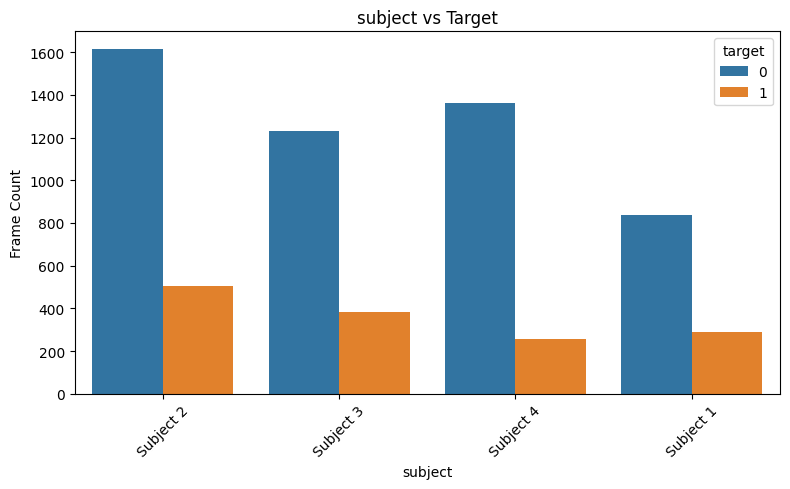

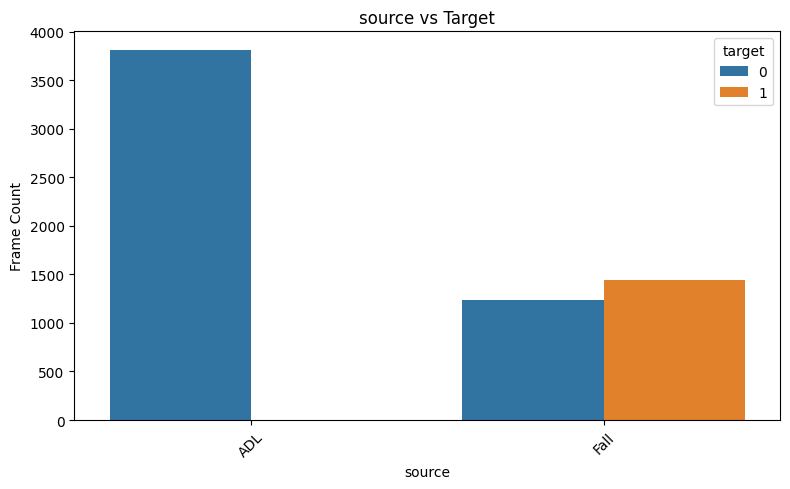

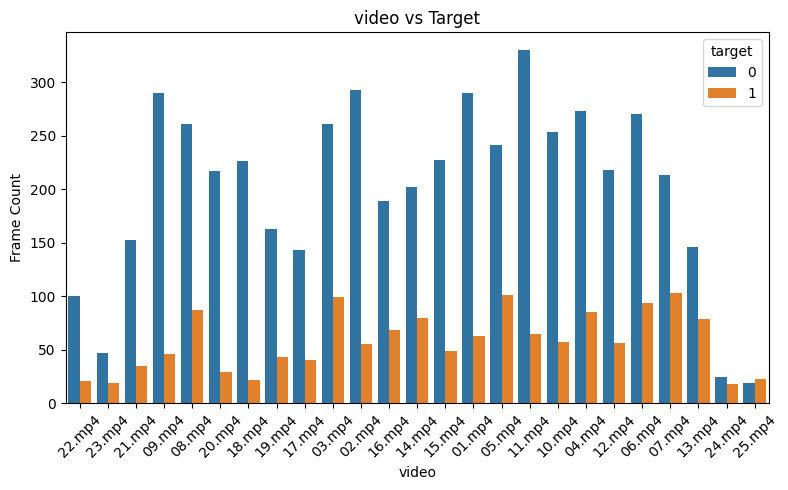

In [11]:
# ==========================================
# BIVARIATE ANALYSIS
# Categorical Features vs Target
# ==========================================

categorical_features = [
    "subject",
    "source",
    "video"
]

for feature in categorical_features:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=feature,
        hue="target"
    )

    plt.title(f"{feature} vs Target")
    plt.xlabel(feature)
    plt.ylabel("Frame Count")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

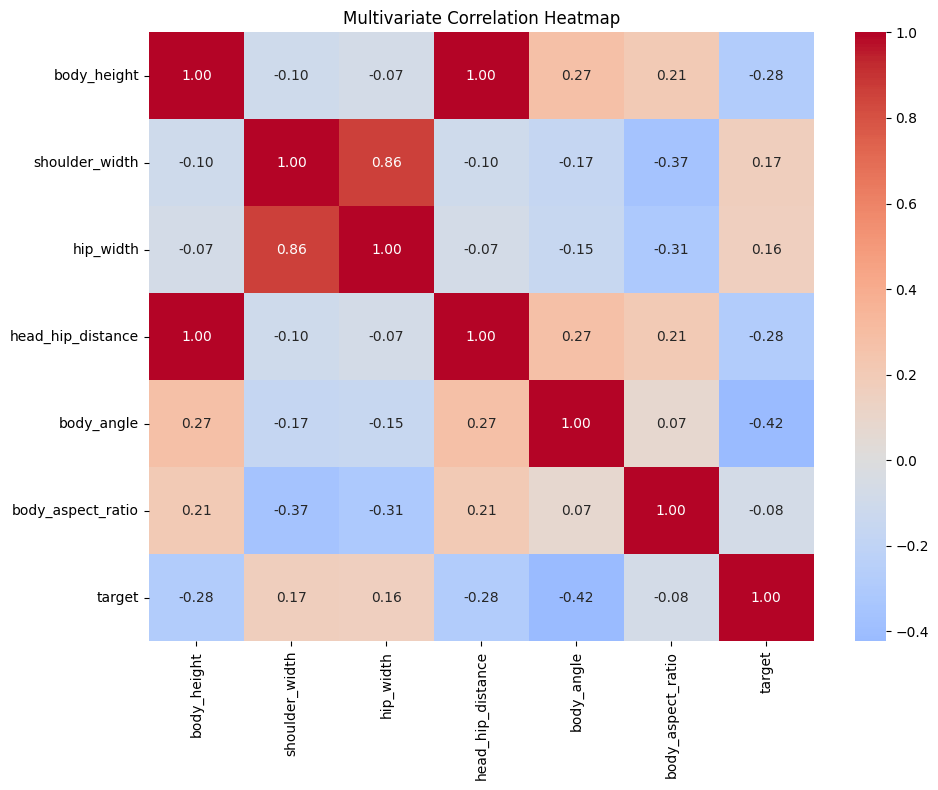

In [12]:
# ==========================================
# MULTIVARIATE ANALYSIS
# ==========================================

multivariate_features = [
    "body_height",
    "shoulder_width",
    "hip_width",
    "head_hip_distance",
    "body_angle",
    "body_aspect_ratio"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    df[multivariate_features + ["target"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Multivariate Correlation Heatmap")
plt.tight_layout()
plt.show()

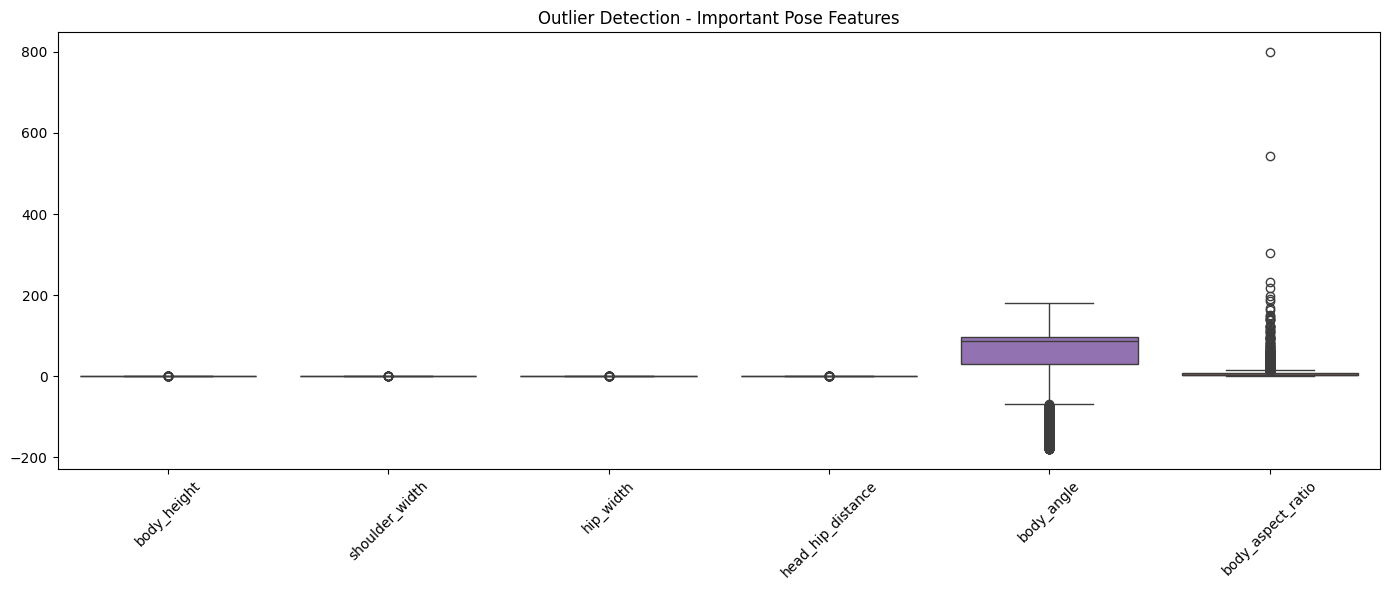

In [13]:
# ==========================================
# OUTLIER DETECTION
# ==========================================

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df[multivariate_features]
)

plt.title("Outlier Detection - Important Pose Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 🔹 EDA — Business Insights

From everything we've analyzed so far, these are the important insights:

- Target imbalance:
Normal = 77.84%, Fall = 22.16% → moderate imbalance.
- Fall frames:
Fall samples are present only in source = Fall, while ADL is normal.
- Strong feature relationship:
body_angle ↔ target = -0.42 → currently the strongest individual correlation with fall.
- Redundancy:
body_height ↔ head_hip_distance = 1.00 → nearly identical information.
- Strong feature correlation:
shoulder_width ↔ hip_width = 0.86.
- Outliers:
Many extreme values exist, especially in body_angle and body_aspect_ratio, but we should not automatically remove them because extreme poses can represent actual falls.

In [14]:
# ============================================
# STEP 6: FEATURE ENGINEERING
# ============================================

# Body height
df["body_height"] = np.sqrt(
    (df["x_0"] - df["x_24"]) ** 2 +
    (df["y_0"] - df["y_24"]) ** 2
)

# Shoulder width
df["shoulder_width"] = np.sqrt(
    (df["x_11"] - df["x_12"]) ** 2 +
    (df["y_11"] - df["y_12"]) ** 2
)

# Hip width
df["hip_width"] = np.sqrt(
    (df["x_23"] - df["x_24"]) ** 2 +
    (df["y_23"] - df["y_24"]) ** 2
)

# Head-to-hip distance
df["head_hip_distance"] = np.sqrt(
    (df["x_0"] - df["x_24"]) ** 2 +
    (df["y_0"] - df["y_24"]) ** 2
)

# Body angle
df["body_angle"] = np.degrees(
    np.arctan2(
        df["y_24"] - df["y_0"],
        df["x_24"] - df["x_0"]
    )
)

# Body aspect ratio
df["body_aspect_ratio"] = (
    df["body_height"] /
    (df["shoulder_width"] + 1e-6)
)

print("===================================")
print("FEATURE ENGINEERING COMPLETED")
print("===================================")

print("Dataset Shape:", df.shape)

print("\nNew Features:")
print([
    "body_height",
    "shoulder_width",
    "hip_width",
    "head_hip_distance",
    "body_angle",
    "body_aspect_ratio"
])

print("\nLast 6 Columns:")
display(df.tail()[[
    "body_height",
    "shoulder_width",
    "hip_width",
    "head_hip_distance",
    "body_angle",
    "body_aspect_ratio"
]])

FEATURE ENGINEERING COMPLETED
Dataset Shape: (6485, 144)

New Features:
['body_height', 'shoulder_width', 'hip_width', 'head_hip_distance', 'body_angle', 'body_aspect_ratio']

Last 6 Columns:


,body_height,shoulder_width,hip_width,head_hip_distance,body_angle,body_aspect_ratio
6480,0.147428,0.026459,0.022222,0.147428,73.909190,5.571838
6481,0.148814,0.018745,0.018884,0.148814,73.414625,7.938287
6482,0.156065,0.020865,0.017135,0.156065,73.253398,7.479347
6483,0.162042,0.029262,0.019425,0.162042,74.234239,5.537445
6484,0.162961,0.036466,0.024980,0.162961,74.552005,4.468685


In [15]:
# ============================================
# STEP 7: DEFINE X AND y
# ============================================

# Metadata columns are not ML features
metadata_columns = [
    "subject",
    "video",
    "source",
    "frame",
    "time_seconds"
]

# Target
y = df["target"]

# Features
X = df.drop(
    columns=metadata_columns + ["target"]
)

print("===================================")
print("X AND y DEFINED")
print("===================================")

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

print("\nNumber of Features:", X.shape[1])

X AND y DEFINED
X Shape: (6485, 138)
y Shape: (6485,)

Target Distribution:
target
0    5048
1    1437
Name: count, dtype: int64

Number of Features: 138


In [16]:
# ============================================
# STEP 8: GROUP-BASED TRAIN TEST SPLIT
# ============================================

# Create a unique group for each subject + video
groups = (
    df["subject"].astype(str)
    + "_"
    + df["video"].astype(str)
)

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        X,
        y,
        groups=groups
    )
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("===================================")
print("GROUP-BASED TRAIN TEST SPLIT")
print("===================================")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\ny_train:")
print(y_train.value_counts())

print("\ny_test:")
print(y_test.value_counts())

# Verify no group leakage
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("\nOverlapping Groups:")
print(train_groups.intersection(test_groups))

print("\nTrain/Test split completed.")

GROUP-BASED TRAIN TEST SPLIT
X_train: (5094, 138)
X_test : (1391, 138)

y_train:
target
0    4002
1    1092
Name: count, dtype: int64

y_test:
target
0    1046
1     345
Name: count, dtype: int64

Overlapping Groups:
set()

Train/Test split completed.


In [17]:
# ============================================
# STEP 9: PREPROCESSING
# ============================================

# Imputer
imputer = SimpleImputer(
    strategy="median"
)

X_train_imputed = imputer.fit_transform(
    X_train
)

X_test_imputed = imputer.transform(
    X_test
)

# Scaler
scaler = StandardScaler()

X_train_processed = scaler.fit_transform(
    X_train_imputed
)

X_test_processed = scaler.transform(
    X_test_imputed
)

# Convert to float32 for ANN compatibility
X_train_processed = X_train_processed.astype(
    np.float32
)

X_test_processed = X_test_processed.astype(
    np.float32
)

print("===================================")
print("PREPROCESSING COMPLETED")
print("===================================")

print(
    "X_train:",
    X_train_processed.shape
)

print(
    "X_test:",
    X_test_processed.shape
)

print(
    "Missing values in train:",
    np.isnan(X_train_processed).sum()
)

print(
    "Missing values in test:",
    np.isnan(X_test_processed).sum()
)

PREPROCESSING COMPLETED
X_train: (5094, 138)
X_test: (1391, 138)
Missing values in train: 0
Missing values in test: 0


In [18]:
# ============================================
# STEP 10: ML BASELINE MODELS
# ============================================

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ),

    "KNN":
        KNeighborsClassifier(
            n_neighbors=5
        ),

    "Naive Bayes":
        GaussianNB(),

    "SVM":
        SVC(
            random_state=42
        )
}

results = []

for name, model in models.items():

    print(f"Training: {name}")

    model.fit(
        X_train_processed,
        y_train
    )

    y_pred = model.predict(
        X_test_processed
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test,
            y_pred
        ),
        "Precision": precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            y_pred,
            zero_division=0
        )
    })

# ============================================
# RESULTS
# ============================================

ml_results = pd.DataFrame(results)

ml_results = ml_results.sort_values(
    by="F1",
    ascending=False
)

print("\n===================================")
print("ML BASELINE RESULTS")
print("===================================")

display(ml_results)

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: KNN
Training: Naive Bayes
Training: SVM

ML BASELINE RESULTS


,Model,Accuracy,Precision,Recall,F1
4,Naive Bayes,0.809490,0.590909,0.753623,0.662420
2,Random Forest,0.834651,0.720307,0.544928,0.620462
3,KNN,0.829619,0.716000,0.518841,0.601681
5,SVM,0.803738,0.624138,0.524638,0.570079
0,Logistic Regression,0.817398,0.685714,0.486957,0.569492
1,Decision Tree,0.746226,0.491228,0.649275,0.559301


In [19]:
# ============================================
# STEP 11: ARTIFICIAL NEURAL NETWORK
# ============================================

ann = Sequential([

    tf.keras.Input(
        shape=(X_train_processed.shape[1],)
    ),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.20),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

# ============================================
# COMPILE
# ============================================

ann.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# ============================================
# EARLY STOPPING
# ============================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# ============================================
# TRAIN
# ============================================

history = ann.fit(
    X_train_processed,
    y_train,
    validation_split=0.20,
    epochs=50,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

print("===================================")
print("ANN TRAINING COMPLETED")
print("===================================")

Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8052 - loss: 0.4222 - val_accuracy: 0.7870 - val_loss: 0.4697
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8974 - loss: 0.2675 - val_accuracy: 0.7949 - val_loss: 0.4403
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9099 - loss: 0.2429 - val_accuracy: 0.7870 - val_loss: 0.4575
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9175 - loss: 0.2240 - val_accuracy: 0.7939 - val_loss: 0.4514
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9190 - loss: 0.2097 - val_accuracy: 0.8018 - val_loss: 0.4531
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9232 - loss: 0.2086 - val_accuracy: 0.7988 - val_loss: 0.4689
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9266 - loss: 0.1997 - val_accuracy: 0.8194 - val_loss: 0.4425
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9296 - loss: 0.1867 - val_accuracy: 0.8086 - val_loss

In [20]:
# ============================================
# STEP 12: ANN EVALUATION
# ============================================

# Prediction probabilities
ann_probabilities = ann.predict(
    X_test_processed,
    verbose=0
).ravel()

# Convert probabilities to class
ann_predictions = (
    ann_probabilities >= 0.5
).astype(int)

# Metrics
ann_accuracy = accuracy_score(
    y_test,
    ann_predictions
)

ann_precision = precision_score(
    y_test,
    ann_predictions,
    zero_division=0
)

ann_recall = recall_score(
    y_test,
    ann_predictions,
    zero_division=0
)

ann_f1 = f1_score(
    y_test,
    ann_predictions,
    zero_division=0
)

ann_roc_auc = roc_auc_score(
    y_test,
    ann_probabilities
)

print("===================================")
print("ANN EVALUATION")
print("===================================")

print(f"Accuracy : {ann_accuracy:.4f}")
print(f"Precision: {ann_precision:.4f}")
print(f"Recall   : {ann_recall:.4f}")
print(f"F1 Score : {ann_f1:.4f}")
print(f"ROC-AUC  : {ann_roc_auc:.4f}")

# ============================================
# CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_test,
    ann_predictions
)

print("\n===================================")
print("CONFUSION MATRIX")
print("===================================")

print(cm)

# ============================================
# CLASSIFICATION REPORT
# ============================================

print("\n===================================")
print("CLASSIFICATION REPORT")
print("===================================")

print(
    classification_report(
        y_test,
        ann_predictions,
        target_names=[
            "Normal",
            "Fall"
        ],
        zero_division=0
    )
)

ANN EVALUATION
Accuracy : 0.7843
Precision: 0.5949
Recall   : 0.4087
F1 Score : 0.4845
ROC-AUC  : 0.8471

CONFUSION MATRIX
[[950  96]
 [204 141]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.82      0.91      0.86      1046
        Fall       0.59      0.41      0.48       345

    accuracy                           0.78      1391
   macro avg       0.71      0.66      0.67      1391
weighted avg       0.77      0.78      0.77      1391



In [21]:
# ============================================
# STEP 13: ANN HYPERPARAMETER TUNING
# ============================================

from itertools import product
from sklearn.metrics import f1_score

# ============================================
# HYPERPARAMETERS
# ============================================

units_1 = [32, 64, 128]
units_2 = [16, 32]
dropouts = [0.1, 0.2]
batch_sizes = [64, 128]

best_f1 = 0
best_params = None
best_ann = None

tuning_results = []

# ============================================
# TUNING
# ============================================

for u1, u2, dropout, batch_size in product(
    units_1,
    units_2,
    dropouts,
    batch_sizes
):

    model = Sequential([

        tf.keras.Input(
            shape=(X_train_processed.shape[1],)
        ),

        Dense(
            u1,
            activation="relu"
        ),

        Dropout(dropout),

        Dense(
            u2,
            activation="relu"
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        X_train_processed,
        y_train,
        validation_split=0.20,
        epochs=20,
        batch_size=batch_size,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    probabilities = model.predict(
        X_test_processed,
        verbose=0
    ).ravel()

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    tuning_results.append({
        "units_1": u1,
        "units_2": u2,
        "dropout": dropout,
        "batch_size": batch_size,
        "F1": f1
    })

    if f1 > best_f1:
        best_f1 = f1
        best_params = {
            "units_1": u1,
            "units_2": u2,
            "dropout": dropout,
            "batch_size": batch_size
        }
        best_ann = model

# ============================================
# RESULTS
# ============================================

ann_tuning_results = pd.DataFrame(
    tuning_results
).sort_values(
    by="F1",
    ascending=False
)

print("===================================")
print("ANN HYPERPARAMETER TUNING")
print("===================================")

display(
    ann_tuning_results.head(10)
)

print("\nBest Parameters:")
print(best_params)

print("\nBest F1:")
print(best_f1)

ANN HYPERPARAMETER TUNING


,units_1,units_2,dropout,batch_size,F1
3,32,16,0.2,128,0.592000
8,64,16,0.1,64,0.574394
4,32,32,0.1,64,0.573770
11,64,16,0.2,128,0.542609
13,64,32,0.1,128,0.537563
9,64,16,0.1,128,0.534224
22,128,32,0.2,64,0.525180
7,32,32,0.2,128,0.525043
23,128,32,0.2,128,0.522202
15,64,32,0.2,128,0.520064



Best Parameters:
{'units_1': 32, 'units_2': 16, 'dropout': 0.2, 'batch_size': 128}

Best F1:
0.592


In [22]:
# ============================================
# STEP 14: ML HYPERPARAMETER TUNING
# ============================================

from sklearn.model_selection import GridSearchCV

# --------------------------------------------
# 1. LOGISTIC REGRESSION
# --------------------------------------------

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000),
    {
        "C": [0.01, 0.1, 1, 10],
        "solver": ["lbfgs"]
    },
    scoring="f1",
    cv=5,
    n_jobs=-1
)

lr_grid.fit(
    X_train_processed,
    y_train
)


# --------------------------------------------
# 2. RANDOM FOREST
# --------------------------------------------

rf_grid = GridSearchCV(
    RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5]
    },
    scoring="f1",
    cv=5,
    n_jobs=-1
)

rf_grid.fit(
    X_train_processed,
    y_train
)


# --------------------------------------------
# 3. KNN
# --------------------------------------------

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    {
        "n_neighbors": [3, 5, 7, 9, 11],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    },
    scoring="f1",
    cv=5,
    n_jobs=-1
)

knn_grid.fit(
    X_train_processed,
    y_train
)


# --------------------------------------------
# RESULTS
# --------------------------------------------

tuned_models = {
    "Logistic Regression": lr_grid,
    "Random Forest": rf_grid,
    "KNN": knn_grid
}

tuned_results = []

for name, grid in tuned_models.items():

    predictions = grid.predict(
        X_test_processed
    )

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })

tuned_ml_results = pd.DataFrame(
    tuned_results
).sort_values(
    by="F1",
    ascending=False
)

print("===================================")
print("TUNED ML RESULTS")
print("===================================")

display(tuned_ml_results)

print("\n===================================")
print("BEST PARAMETERS")
print("===================================")

print("\nLogistic Regression:")
print(lr_grid.best_params_)

print("\nRandom Forest:")
print(rf_grid.best_params_)

print("\nKNN:")
print(knn_grid.best_params_)

TUNED ML RESULTS


,Model,Accuracy,Precision,Recall,F1
1,Random Forest,0.841840,0.734082,0.568116,0.640523
2,KNN,0.831057,0.711538,0.536232,0.611570
0,Logistic Regression,0.823149,0.736842,0.446377,0.555957



BEST PARAMETERS

Logistic Regression:
{'C': 0.01, 'solver': 'lbfgs'}

Random Forest:
{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}

KNN:
{'n_neighbors': 11, 'p': 1, 'weights': 'uniform'}


In [23]:
# ============================================
# STEP 15: FINAL MODEL COMPARISON
# ============================================

# Best tuned Random Forest
best_rf = rf_grid.best_estimator_

rf_prob = best_rf.predict_proba(
    X_test_processed
)[:, 1]

rf_pred = best_rf.predict(
    X_test_processed
)

# Tuned ANN
ann_prob = best_ann.predict(
    X_test_processed,
    verbose=0
).ravel()

ann_pred = (
    ann_prob >= 0.5
).astype(int)

final_results = pd.DataFrame([

    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred),
        "Recall": recall_score(y_test, rf_pred),
        "F1": f1_score(y_test, rf_pred),
        "ROC-AUC": roc_auc_score(y_test, rf_prob)
    },

    {
        "Model": "ANN",
        "Accuracy": accuracy_score(y_test, ann_pred),
        "Precision": precision_score(y_test, ann_pred),
        "Recall": recall_score(y_test, ann_pred),
        "F1": f1_score(y_test, ann_pred),
        "ROC-AUC": roc_auc_score(y_test, ann_prob)
    }

])

final_results = final_results.sort_values(
    by="F1",
    ascending=False
)

print("===================================")
print("FINAL MODEL COMPARISON")
print("===================================")

display(final_results)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.841840,0.734082,0.568116,0.640523,0.910292
1,ANN,0.816679,0.660714,0.536232,0.592000,0.866991


In [24]:
# ============================================
# STEP 16: SAVE BEST MODEL
# ============================================

import joblib

final_model = {
    "model": best_rf,
    "imputer": imputer,
    "scaler": scaler,
    "feature_names": X.columns.tolist()
}

joblib.dump(
    final_model,
    "/content/fall_detection_model.pkl"
)

print("===================================")
print("MODEL SAVED")
print("===================================")

print("File:")
print("/content/fall_detection_model.pkl")

MODEL SAVED
File:
/content/fall_detection_model.pkl


In [25]:
# ============================================
# STEP 17: DOWNLOAD MODEL
# ============================================

from google.colab import files

files.download(
    "/content/fall_detection_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
# ============================================
# STEP 18: VERIFY SAVED MODEL
# ============================================

import joblib

loaded_model = joblib.load(
    "/content/fall_detection_model.pkl"
)

print("===================================")
print("MODEL VERIFICATION")
print("===================================")

print("Model loaded successfully")

print("\nModel Type:")
print(type(loaded_model["model"]))

print("\nNumber of Features:")
print(len(loaded_model["feature_names"]))

print("\nSaved Objects:")
print(loaded_model.keys())

MODEL VERIFICATION
Model loaded successfully

Model Type:
<class 'sklearn.ensemble._forest.RandomForestClassifier'>

Number of Features:
138

Saved Objects:
dict_keys(['model', 'imputer', 'scaler', 'feature_names'])
